# Aqua-Epoch: Task A → Task B stacked model

This model-only notebook implements both challenge tasks. First it predicts water safety and a Safe probability. Then it estimates pH using all chemical measurements plus that **predicted** Safe probability. The pH model is robust Huber gradient boosting, selected after validation against Random Forest, Extra Trees, histogram gradient boosting, LightGBM and XGBoost candidates.

The true `Potability` label is never sent into the pH model for a new sample. During training, out-of-fold classifier predictions prevent target leakage.

In [1]:
cd /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete

python3 -m venv .venv
source .venv/bin/activate

pip install -r requirements.txt

python run.py train
python run.py serve

SyntaxError: invalid syntax. Perhaps you forgot a comma? (622312094.py, line 3)

In [ ]:
from __future__ import annotations

import json
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

SPLIT_SEED = 15
MODEL_SEED = 42
TEST_SIZE = 0.23

CLASSIFICATION_FEATURES = [
    'Turbidity', 'Hardness', 'TDS', 'Fluoride', 'Nitrate', 'Conductivity',
]
CHEMISTRY_FEATURES = [
    'Hardness', 'TDS', 'Chloramines', 'Sulfate', 'Conductivity',
    'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Calcium',
    'Magnesium', 'Sodium', 'Potassium', 'Chloride', 'Nitrate',
    'Fluoride', 'Iron', 'Alkalinity',
]
SAFE_PROBABILITY_FEATURE = 'predicted_safe_probability'
PH_FEATURES = CHEMISTRY_FEATURES + [SAFE_PROBABILITY_FEATURE]

## 1. Load and clean the data

In [ ]:
DATASET_NAME = 'Aqua_Epoch_BIS_Water_Quality_Dataset.csv'
possible_paths = [
    candidate / 'data' / DATASET_NAME
    for root in [Path.cwd(), *Path.cwd().parents]
    for candidate in (root, root / 'aqua_epoch_complete')
]
DATA_PATH = next((path for path in possible_paths if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Could not find {DATASET_NAME} in a data/ folder.')

PROJECT_ROOT = DATA_PATH.parent.parent
df = pd.read_csv(DATA_PATH)
required = CHEMISTRY_FEATURES + ['pH', 'Potability']
for column in required:
    df[column] = pd.to_numeric(df[column], errors='coerce')

valid_rows = (
    (df['pH'].isna() | df['pH'].between(0, 14))
    & (df['Hardness'].isna() | df['Hardness'].ge(0))
    & df['TDS'].between(50, 50_000)
    & (df['Fluoride'].isna() | df['Fluoride'].ge(0))
    & (df['Nitrate'].isna() | df['Nitrate'].le(100))
    & (df['Potassium'].isna() | df['Potassium'].le(40))
)
df = df.loc[valid_rows].reset_index(drop=True)
print(f'Cleaned rows: {len(df):,}')
display(df[CHEMISTRY_FEATURES + ['pH', 'Potability']].head())

Cleaned rows: 21,756


,Hardness,TDS,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Calcium,Magnesium,Sodium,Potassium,Chloride,Nitrate,Fluoride,Iron,Alkalinity,pH,Potability
0,150.155773,16052.651840,5.685047,374.464185,352.121528,11.587073,75.046610,4.966698,61.504002,21.006579,62.345970,2.192344,135.643193,5.561354,1.520887,0.169315,116.950616,7.159102,0.0
1,212.120116,15569.182870,6.872750,319.992702,443.547183,18.268341,123.893737,2.868158,85.238809,28.953441,79.458626,10.197039,168.585701,61.612777,0.786435,0.065204,152.949912,6.990053,0.0
2,204.571035,8183.078691,5.986018,416.595049,311.932109,12.701190,67.312776,4.264031,77.150948,30.591307,62.537654,10.996049,97.220908,9.129196,0.688611,0.124803,153.344413,7.110356,1.0
3,150.299555,25303.762810,7.147440,352.099179,526.743300,15.772748,51.344206,3.407067,58.647298,17.553237,110.628270,12.754797,196.460217,5.390290,1.300669,0.064911,106.874981,5.500103,0.0
4,210.286583,12656.723620,9.167730,349.388214,597.384394,10.761081,90.919973,4.769402,73.005793,30.096941,103.140817,12.468479,180.730654,51.619932,1.479490,0.126527,154.240181,6.171355,0.0


## 2. Model helper functions

The pH regressor gets a classifier probability, never the actual Potability label. For training rows, that probability is calculated by a classifier that did not train on the same row.

In [ ]:
def make_classifier():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=200, max_depth=12, min_samples_split=10,
            min_samples_leaf=5, max_features=None,
            class_weight='balanced_subsample', random_state=MODEL_SEED, n_jobs=-1,
        )),
    ])

def make_ph_regressor():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', GradientBoostingRegressor(
            n_estimators=250, learning_rate=0.025, max_depth=2,
            min_samples_leaf=30, loss='huber', random_state=MODEL_SEED,
        )),
    ])

def safe_probability(model, features):
    safe_index = list(model.classes_).index(1)
    return model.predict_proba(features)[:, safe_index]

def build_ph_frame(chemistry, probabilities):
    frame = chemistry.copy()
    frame[SAFE_PROBABILITY_FEATURE] = probabilities
    return frame[PH_FEATURES]

def out_of_fold_safe_probabilities(features, labels):
    probabilities = np.empty(len(features))
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SPLIT_SEED)
    for train_positions, valid_positions in folds.split(features, labels):
        fold_model = make_classifier()
        fold_model.fit(features.iloc[train_positions], labels.iloc[train_positions])
        probabilities[valid_positions] = safe_probability(
            fold_model, features.iloc[valid_positions]
        )
    final_classifier = make_classifier()
    final_classifier.fit(features, labels)
    return probabilities, final_classifier

## 3. Task A — Water safety classification

In [ ]:
class_rows = df['Potability'].isin([0, 1])
X_class = df.loc[class_rows, CLASSIFICATION_FEATURES]
y_class = df.loc[class_rows, 'Potability'].astype(int)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class, y_class, test_size=TEST_SIZE, random_state=SPLIT_SEED, stratify=y_class,
)

classifier_evaluation = make_classifier()
classifier_evaluation.fit(Xc_train, yc_train)
class_test_probability = safe_probability(classifier_evaluation, Xc_test)
class_test_prediction = (class_test_probability >= 0.50).astype(int)

classification_metrics = {
    'accuracy': accuracy_score(yc_test, class_test_prediction),
    'roc_auc': roc_auc_score(yc_test, class_test_probability),
}
pd.Series(classification_metrics, name='Task A score').to_frame()

,Task A score
accuracy,0.914868
roc_auc,0.938324


## 4. Task B — pH regression using chemistry + Task A confidence

In [ ]:
# Rows need both a measured pH and a Potability label to create the
# classifier-derived probability used by Task B.
regression_rows = class_rows & df['pH'].notna()
regression_data = df.loc[regression_rows]
X_chemistry = regression_data[CHEMISTRY_FEATURES]
X_regression_class = regression_data[CLASSIFICATION_FEATURES]
y_ph = regression_data['pH']
y_regression_class = regression_data['Potability'].astype(int)

Xchem_train, Xchem_test, Xclass_train, Xclass_test, yph_train, yph_test, yclass_train, _ = train_test_split(
    X_chemistry, X_regression_class, y_ph, y_regression_class,
    test_size=TEST_SIZE, random_state=SPLIT_SEED, stratify=y_regression_class,
)

# Train pH with out-of-fold safety confidence. This prevents leakage.
train_safe_probability, regression_classifier = out_of_fold_safe_probabilities(
    Xclass_train.reset_index(drop=True), yclass_train.reset_index(drop=True)
)
test_safe_probability = safe_probability(regression_classifier, Xclass_test)
Xph_train = build_ph_frame(Xchem_train, train_safe_probability)
Xph_test = build_ph_frame(Xchem_test, test_safe_probability)

ph_regressor_evaluation = make_ph_regressor()
ph_regressor_evaluation.fit(Xph_train, yph_train)
ph_prediction = ph_regressor_evaluation.predict(Xph_test)

ph_metrics = {
    'mae': mean_absolute_error(yph_test, ph_prediction),
    'rmse': float(mean_squared_error(yph_test, ph_prediction) ** 0.5),
    'r2': r2_score(yph_test, ph_prediction),
}
pd.Series(ph_metrics, name='Task B score').to_frame()

,Task B score
mae,0.500482
rmse,0.713722
r2,0.021824


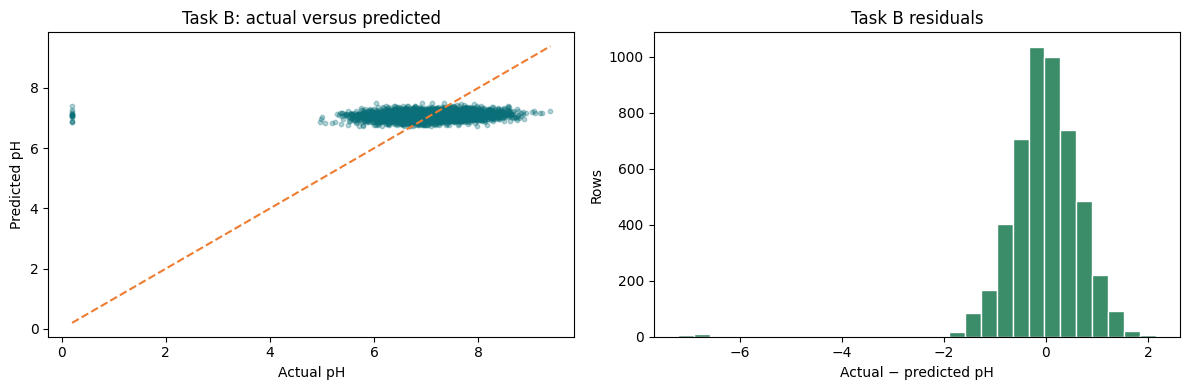

In [ ]:
residuals = yph_test.to_numpy() - ph_prediction
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(yph_test, ph_prediction, alpha=0.3, s=10, color='#0a6f78')
low = min(yph_test.min(), ph_prediction.min())
high = max(yph_test.max(), ph_prediction.max())
axes[0].plot([low, high], [low, high], '--', color='#ee7d32')
axes[0].set(xlabel='Actual pH', ylabel='Predicted pH', title='Task B: actual versus predicted')
axes[1].hist(residuals, bins=30, color='#3b8c68', edgecolor='white')
axes[1].set(xlabel='Actual − predicted pH', ylabel='Rows', title='Task B residuals')
plt.tight_layout()
plt.show()

## 5. Refit on all labelled data and save the two models

Use the saved models in the backend. The pH model requires a full 17-feature chemistry row and the classifier's predicted Safe probability.

In [ ]:
classifier = make_classifier()
classifier.fit(X_class, y_class)

all_safe_probability, _ = out_of_fold_safe_probabilities(
    X_regression_class.reset_index(drop=True), y_regression_class.reset_index(drop=True)
)
Xph_all = build_ph_frame(X_chemistry, all_safe_probability)
ph_regressor = make_ph_regressor()
ph_regressor.fit(Xph_all, y_ph)

# Reuse the project trainer for the final save. It creates the API-compatible
# model files, metadata, evaluation tables, figures and technical report together.
import sys

if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from aqua_epoch.train import train

metadata = train(data_path=DATA_PATH, seed=SPLIT_SEED)
print(f"Saved API-compatible Task A and Task B artifacts: {metadata['model_version']}")

Training classification model on 16,751 rows …


Training full-chemistry pH regression model on 16,713 rows …



Training complete.
Task A ROC-AUC: 0.9383; F1-safe: 0.9017
Task B MAE: 0.5005; RMSE: 0.7137; R²: 0.0218
Models: /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/models
Round 1 PDF: /Users/shubham_kumar/Desktop/Techfest/aqua_epoch_complete/docs/round1_technical_deck.pdf
Saved API-compatible Task A and Task B artifacts: 3.1.0-validated-robust-ph


## 6. Predict one sample

A real prediction first gets the probability from Task A. That probability becomes one of the Task B inputs.

In [ ]:
sample_values = {feature: float(df[feature].median()) for feature in CHEMISTRY_FEATURES}
sample_values.update({'Turbidity': 1.0, 'Hardness': 180.0, 'TDS': 450.0})
sample_chemistry = pd.DataFrame([sample_values])[CHEMISTRY_FEATURES]
sample_classification = sample_chemistry[CLASSIFICATION_FEATURES]
sample_safe_probability = safe_probability(classifier, sample_classification)
sample_ph_frame = build_ph_frame(sample_chemistry, sample_safe_probability)
sample_ph = float(ph_regressor.predict(sample_ph_frame)[0])

print(f'Safe probability: {sample_safe_probability[0]:.2%}')
print(f'Safety label: {"Safe" if sample_safe_probability[0] >= 0.50 else "Unsafe"}')
print(f'Estimated pH: {sample_ph:.2f}')

Safe probability: 29.38%
Safety label: Unsafe
Estimated pH: 7.07
